# Jour 3 — SciPy et statistiques

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1706/chapter/4344), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Exercice 1 — Version

In [2]:
import scipy
from scipy import stats
print("SciPy",scipy.__version__)

SciPy 1.18.1


## Exercice 2 — Statistiques descriptives
SciPy describe utilise la variance d’échantillon (ddof=1). La variance de population est donnée séparément. Médiane et moyenne sont calculées par NumPy, complément numérique de SciPy.

In [3]:
data=np.array([12,15,13,12,18,20,22,21])
desc=stats.describe(data)
print("moyenne",desc.mean,"médiane",np.median(data),"variance échantillon",desc.variance,"écart-type échantillon",np.sqrt(desc.variance))
print("variance population",np.var(data),"écart-type population",np.std(data))

moyenne 16.625 médiane 16.5 variance échantillon 17.125 écart-type échantillon 4.138236339311712
variance population 14.984375 écart-type population 3.8709656418005056


## Exercice 3 — Loi normale

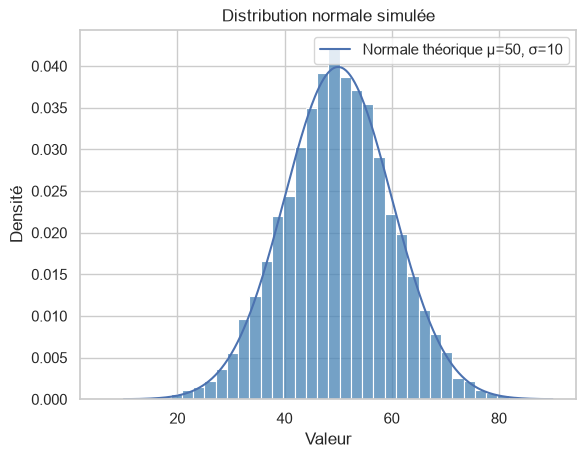

In [4]:
rng=np.random.default_rng(42)
sample=stats.norm.rvs(loc=50,scale=10,size=10000,random_state=rng)
x=np.linspace(10,90,400)
sns.histplot(sample,stat="density",bins=40,color="steelblue")
plt.plot(x,stats.norm.pdf(x,loc=50,scale=10),label="Normale théorique μ=50, σ=10")
plt.xlabel("Valeur");plt.ylabel("Densité");plt.title("Distribution normale simulée");plt.legend();plt.show()

## Exercice 4 — Test t
H0 : mêmes moyennes ; H1 : moyennes différentes. Test bilatéral de Welch pour deux échantillons indépendants, sans imposer l’égalité des variances ; α=0,05. Les observations sont simulées et indépendantes.

In [5]:
data1=rng.normal(50,10,100);data2=rng.normal(60,10,100)
t=stats.ttest_ind(data1,data2,equal_var=False)
print("t",t.statistic,"p",t.pvalue)
print("Rejet de H0" if t.pvalue<.05 else "H0 non rejetée")
print("Différence moyenne simulée",data2.mean()-data1.mean())

t -6.991847173845867 p 4.206912136727873e-11
Rejet de H0
Différence moyenne simulée 10.048597978695526


## Exercice 5 — Régression linéaire

pente 1828.7671232876712 intercept 64383.56164383562 R² 0.9884227164328103
prix prédit à 90 m² 228972.60273972602
Un m² supplémentaire est associé à 1828.77 unités monétaires de plus dans cet échantillon.


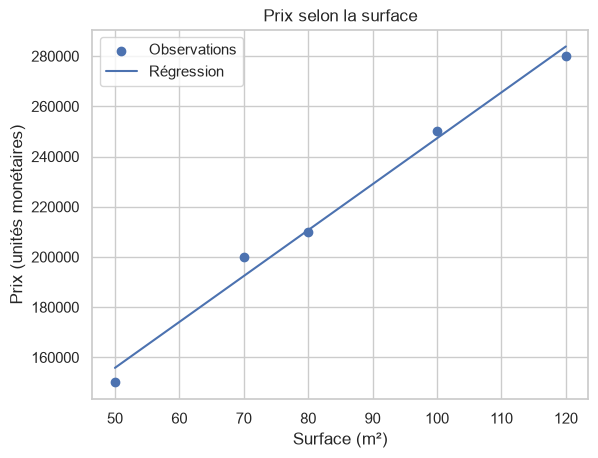

In [6]:
sizes=np.array([50,70,80,100,120]);prices=np.array([150000,200000,210000,250000,280000])
reg=stats.linregress(sizes,prices)
print("pente",reg.slope,"intercept",reg.intercept,"R²",reg.rvalue**2)
print("prix prédit à 90 m²",reg.intercept+reg.slope*90)
print(f"Un m² supplémentaire est associé à {reg.slope:.2f} unités monétaires de plus dans cet échantillon.")
plt.scatter(sizes,prices,label="Observations");plt.plot(sizes,reg.intercept+reg.slope*sizes,label="Régression")
plt.xlabel("Surface (m²)");plt.ylabel("Prix (unités monétaires)");plt.title("Prix selon la surface");plt.legend();plt.show()

Cinq observations seulement : prédiction indicative, sans effet causal démontré, et sans validation hors échantillon.

## Exercice 6 — ANOVA
H0 : les trois moyennes sont égales. L’ANOVA suppose indépendance, résidus approximativement normaux et variances comparables. Les groupes sont petits ; l’expérience doit garantir l’indépendance.

In [7]:
g1=[5,6,7,6,5];g2=[7,8,7,9,8];g3=[4,5,4,3,4]
a=stats.f_oneway(g1,g2,g3)
print("F",a.statistic,"p",a.pvalue)
print("Au moins une moyenne diffère" if a.pvalue<.05 else "Différence non démontrée à 5 %")
print("Moyennes",*[np.mean(g) for g in [g1,g2,g3]])

F 28.52631578947368 p 2.7542672098048448e-05
Au moins une moyenne diffère
Moyennes 5.8 7.8 4.0


Avec p>0,05, on ne rejetterait pas H0 : cela ne prouverait pas l’égalité. Avec p<0,05, un test post-hoc serait nécessaire pour identifier les paires différentes.

## Exercice 7 — Binomiale (optionnel standard)

P(exactement 5 faces en 10 lancers équilibrés indépendants) 0.2460937500000002


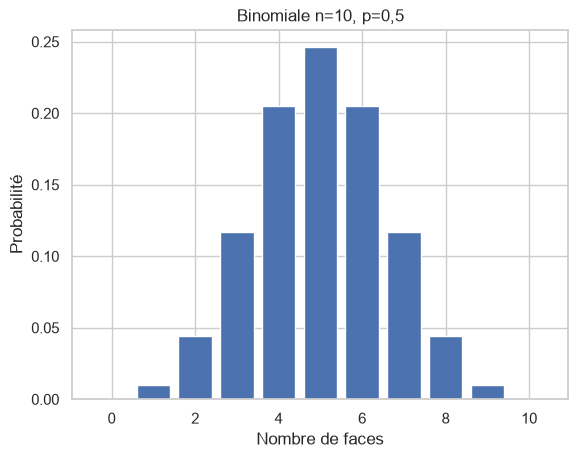

In [8]:
prob=stats.binom.pmf(5,n=10,p=.5)
print("P(exactement 5 faces en 10 lancers équilibrés indépendants)",prob)
k=np.arange(11);plt.bar(k,stats.binom.pmf(k,10,.5));plt.xlabel("Nombre de faces");plt.ylabel("Probabilité");plt.title("Binomiale n=10, p=0,5");plt.show()

## Exercice 8 — Corrélations (optionnel standard)

In [9]:
age=[23,25,30,35,40];income=[35000,40000,50000,60000,70000]
print("Pearson",stats.pearsonr(age,income));print("Spearman",stats.spearmanr(age,income))

Pearson PearsonRResult(statistic=np.float64(0.9996907452347201), pvalue=np.float64(6.528122732016004e-06))
Spearman SignificanceResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(1.4042654220543602e-24))


Pearson mesure l’association linéaire ; Spearman l’association monotone des rangs. Ici le revenu augmente avec l’âge dans les cinq points donnés. Une forte corrélation sur ce petit exemple ne démontre aucune causalité.